# Let's create baseline model after exploring train.csv from Sales_Prediction.ipynb only at first

In [3]:
import pandas as pd 
import datetime as dt 
import numpy as np 
import seaborn as sns

df=pd.read_csv('../data/train.csv',index_col='id')


In [4]:
df['date']=pd.to_datetime(df['date'])
df['store_nbr']=df['store_nbr'].astype('object')

In [5]:
x=df.drop(columns=['sales'])
y=df['sales']
x['dayofweek']=x['date'].dt.day_of_week
x['monthofyear']=x['date'].dt.month
x['year']=x['date'].dt.year
x['isweekend']=x['dayofweek'].isin([5,6])
x['dayofmonth']=x['date'].dt.day
x['dayofweek']=x['date'].dt.day_of_week
x['monthofyear']=x['date'].dt.month
x['year']=x['date'].dt.year
x['isweekend']=x['dayofweek'].isin([5,6])
x['dayofmonth']=x['date'].dt.day

In [6]:
unique_dates=x['date'].unique()
test_dates=unique_dates[-16:]
test_mask=x['date'].isin(test_dates)

x_train,y_train=x[~test_mask].copy(), y[~test_mask].copy()
x_test,y_test=x[test_mask].copy(), y[test_mask].copy()

x_test['date'].nunique()

16

In [7]:
x_train.dtypes

date           datetime64[ns]
store_nbr              object
family                 object
onpromotion             int64
dayofweek               int32
monthofyear             int32
year                    int32
isweekend                bool
dayofmonth              int32
dtype: object

In [8]:
x_train.drop(columns=['date'],inplace=True)
x_test.drop(columns=['date'],inplace=True)
x_train.head()

,store_nbr,family,onpromotion,dayofweek,monthofyear,year,isweekend,dayofmonth
id,,,,,,,,
0,1,AUTOMOTIVE,0,1,1,2013,False,1
1,1,BABY CARE,0,1,1,2013,False,1
2,1,BEAUTY,0,1,1,2013,False,1
3,1,BEVERAGES,0,1,1,2013,False,1
4,1,BOOKS,0,1,1,2013,False,1


In [9]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.base import BaseEstimator,TransformerMixin
from feature_engine.creation import CyclicalFeatures
from sklearn.compose import ColumnTransformer

class mycfe(BaseEstimator,TransformerMixin):

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        x=X.copy()
        month = x['monthofyear'].to_numpy()
        day = x['dayofmonth'].to_numpy()
        year=x['year'].to_numpy()

        days_in_month = np.select( 
            [
                np.isin(month, [1, 3, 5, 7, 8, 10, 12]),
                np.isin(month, [4, 6, 9, 11]),
                (month ==2 ) & (((year % 4 ==0) & (year % 100!= 0)) | (year % 400==0)),
                (month == 2)
            ],
            [31, 30, 29,28],
            default=np.nan
        )

        angle = 2 * np.pi * (day - 1) / days_in_month
        x['day_sin']=np.sin(angle)
        x['day_cos']=np.cos(angle)
        x.drop(columns=['monthofyear'],inplace=True)
        return x
    
    def get_feature_names_out(self, input_features=None):
        return np.array(['year','day_sin','day_cos'], dtype=object)

preprocessor=ColumnTransformer(transformers=[
    ('onehot_encoder',OneHotEncoder(sparse_output=True,handle_unknown='ignore'),['store_nbr','family']),
    ('cyclic_encoder1',CyclicalFeatures(max_values={'dayofweek':7,'monthofyear':12}),['dayofweek','monthofyear']),
    ('cyclic_encoder2',mycfe(),['dayofmonth','monthofyear','year']),               #encodes dayofmonth
],remainder='passthrough')
x_train_processed=preprocessor.fit_transform(x_train)
x_test_processed=preprocessor.transform(x_test)


In [10]:
x_train_processed.shape

(2972376, 99)

<Axes: xlabel='sales'>

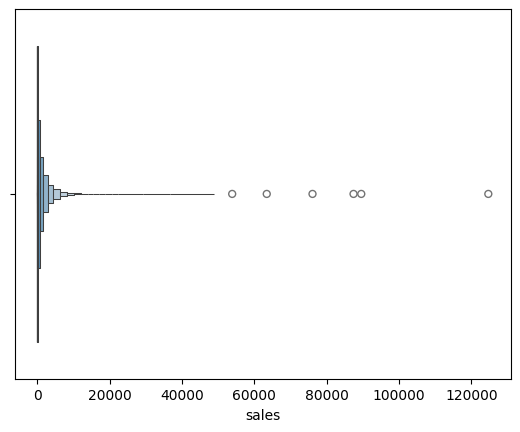

In [27]:
sns.boxenplot(x=y_train)

In [11]:
y_train_log=np.log1p(y_train)
y_test_log=np.log1p(y_test)

In [12]:
from sklearn.linear_model import LinearRegression
from xgboost import XGBRegressor
from sklearn.metrics import root_mean_squared_log_error
lr=LinearRegression()
xgbr=XGBRegressor(device='cuda')    

In [13]:
lr.fit(x_train_processed,y_train_log)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [14]:
y_predict1=np.expm1(lr.predict(x_test_processed))
root_mean_squared_log_error(y_test,y_predict1)

1.0996870045111395

In [15]:
xgbr.fit(x_train_processed,y_train_log)

,objective,'reg:squarederror'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,'cuda'
,early_stopping_rounds,None
,enable_categorical,True
,eval_metric,None


In [16]:
y_predict2=np.expm1(xgbr.predict(x_test_processed))
root_mean_squared_log_error(y_test,y_predict2)

/home/umesh/ML/.venv/lib/python3.14/site-packages/xgboost/core.py:569: UserWarning: [08:43:22] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


0.5968419891927986

# So we will go with xgboost 